[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/market_speed.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# How long until the market knows? The Margin Call question, with spectral graphs

Economic Networks, Part 2  

In Margin Call (2011) a bank decides overnight to sell its toxic assets  
before the rest of the market realises what they are worth. Its window is  
the time it takes for the news to spread from counterparty to counterparty.  

Here, 20 banks trade with each other in networks of different shapes. One bank  
starts selling. Each hour, every bank that has noticed tells each of its trading  
partners with probability Q (an SI spreading model: nobody "un-notices").  
We measure how many hours pass until half, and then 90%, of the market knows,  
and compare with two spectral numbers of each network:  

algebraic connectivity (the Fiedler value): the second-smallest eigenvalue of  
the Laplacian L = D - A. Small when the network has a bottleneck.  
largest eigenvalue of A: grows with hubs and density; it sets how fast  
spreading grows at the start (the 1 / lambda threshold from the SIR slide).  

`Needs: pip install networkx matplotlib numpy`

## Setup

In [1]:
%matplotlib inline

In [2]:
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

N, Q, RUNS, SEED = 20, 0.3, 2000, 1
INK, MUTED, COLORS = "#1B1F3B", "#8A8FA8", ["#8A8FA8", "#E89400", "#F2464F", "#7653E8", "#2D6CF6", "#12A873"]


def markets(n=N, seed=SEED):
    """Six trading networks of 20 banks. Returns {name: (graph, the bank that sells first)}."""
    two = nx.disjoint_union(nx.complete_graph(n // 2), nx.complete_graph(n // 2))
    two.add_edge(n // 2 - 1, n // 2)                       # one bridge between the groups
    core = nx.complete_graph(5)                            # 5 big dealers trade with each other
    rng = random.Random(seed)
    for v in range(5, n):                                  # 15 smaller banks, each with 2 dealers
        for d in rng.sample(range(5), 2):
            core.add_edge(v, d)
    return {
        "A chain": (nx.path_graph(n), 0),
        "A ring": (nx.cycle_graph(n), 0),
        "Two groups, one bridge": (two, 0),
        "Core and periphery": (core, n - 1),
        "Random, 40 links": (nx.gnm_random_graph(n, 40, seed=seed), 0),
        "Everyone trades with everyone": (nx.complete_graph(n), 0),
    }


def spectral(G):
    L = nx.laplacian_matrix(G).toarray().astype(float)
    A = nx.to_numpy_array(G)
    return sorted(np.linalg.eigvalsh(L))[1], max(np.linalg.eigvalsh(A))


def spread(G, seller, rng, max_hours=200):
    """Hour by hour: the share of the OTHER banks that know, until everyone does."""
    knows = {seller}
    shares = [0.0]
    for _ in range(max_hours):
        new = {v for u in knows for v in G[u] if v not in knows and rng.random() < Q}
        knows |= new
        shares.append((len(knows) - 1) / (len(G) - 1))
        if len(knows) == len(G):
            break
    return shares


def hours_until(curves, level):
    """Average hours until `level` of the market knows."""
    return np.mean([next(i for i, s in enumerate(c) if s >= level) for c in curves])


def average_curve(curves, hours):
    return [np.mean([c[min(h, len(c) - 1)] for c in curves]) for h in range(hours + 1)]

## Run everything

In [3]:
rng = random.Random(SEED)
results = {}
print(f"{'Market':32s} {'links':>5s} {'Fiedler':>8s} {'largest eig.':>12s} "
      f"{'hours to 50%':>13s} {'hours to 90%':>13s}")
for name, (G, seller) in markets().items():
    curves = [spread(G, seller, rng) for _ in range(RUNS)]
    fiedler, lam = spectral(G)
    h50, h90 = hours_until(curves, 0.5), hours_until(curves, 0.9)
    results[name] = (G, fiedler, lam, h50, h90, curves)
    print(f"{name:32s} {G.number_of_edges():5d} {fiedler:8.2f} {lam:12.2f} {h50:13.1f} {h90:13.1f}")

Market                           links  Fiedler largest eig.  hours to 50%  hours to 90%


A chain                             19     0.02         1.98          33.2          60.1


A ring                              20     0.10         2.00          16.8          30.1


Two groups, one bridge              91     0.17         9.11           5.4           7.9


Core and periphery                  40     1.33         6.08           4.4           7.0


Random, 40 links                    40     0.61         4.92           3.4           7.0
Everyone trades with everyone      190    20.00        19.00           2.0           2.4


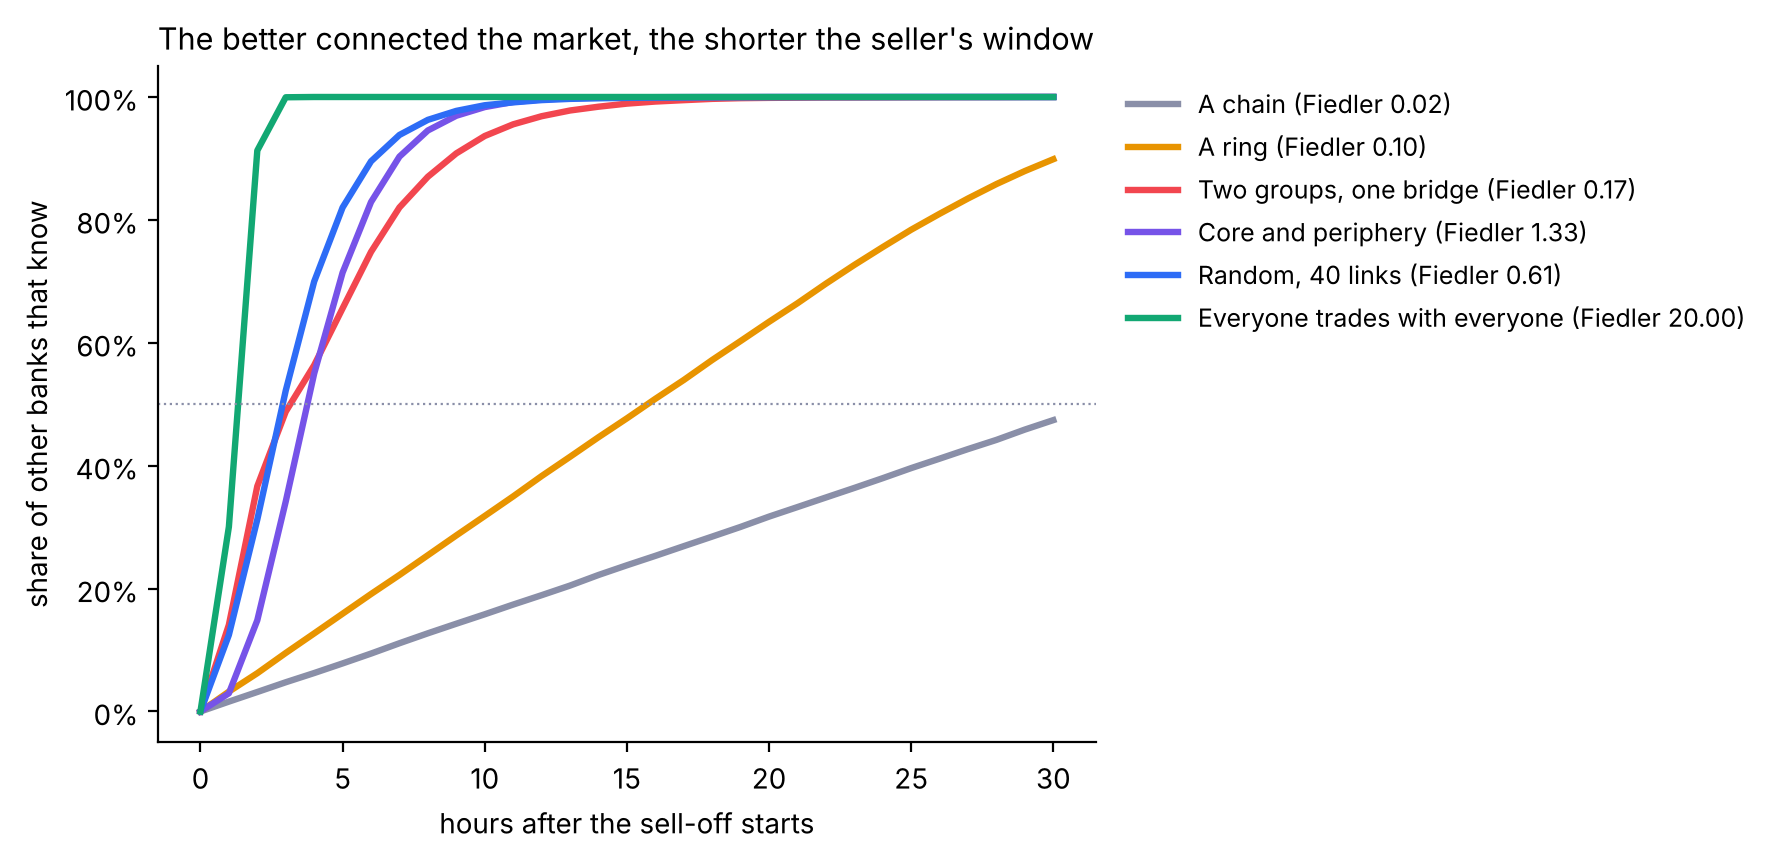

In [4]:
# Figure 1: how fast the market finds out, by network shape
fig, ax = plt.subplots(figsize=(9, 4.4))
for (name, r), col in zip(results.items(), COLORS):
    ax.plot(average_curve(r[5], 30), lw=2.3, color=col, label=f"{name} (Fiedler {r[1]:.2f})")
ax.axhline(0.5, color=MUTED, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("hours after the sell-off starts")
ax.set_ylabel("share of other banks that know")
ax.set_title("The better connected the market, the shorter the seller's window",
             loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout()
fig.savefig("market_fig1_who_knows.png", dpi=160)


Saved market_fig1_who_knows.png and market_fig2_fiedler.png


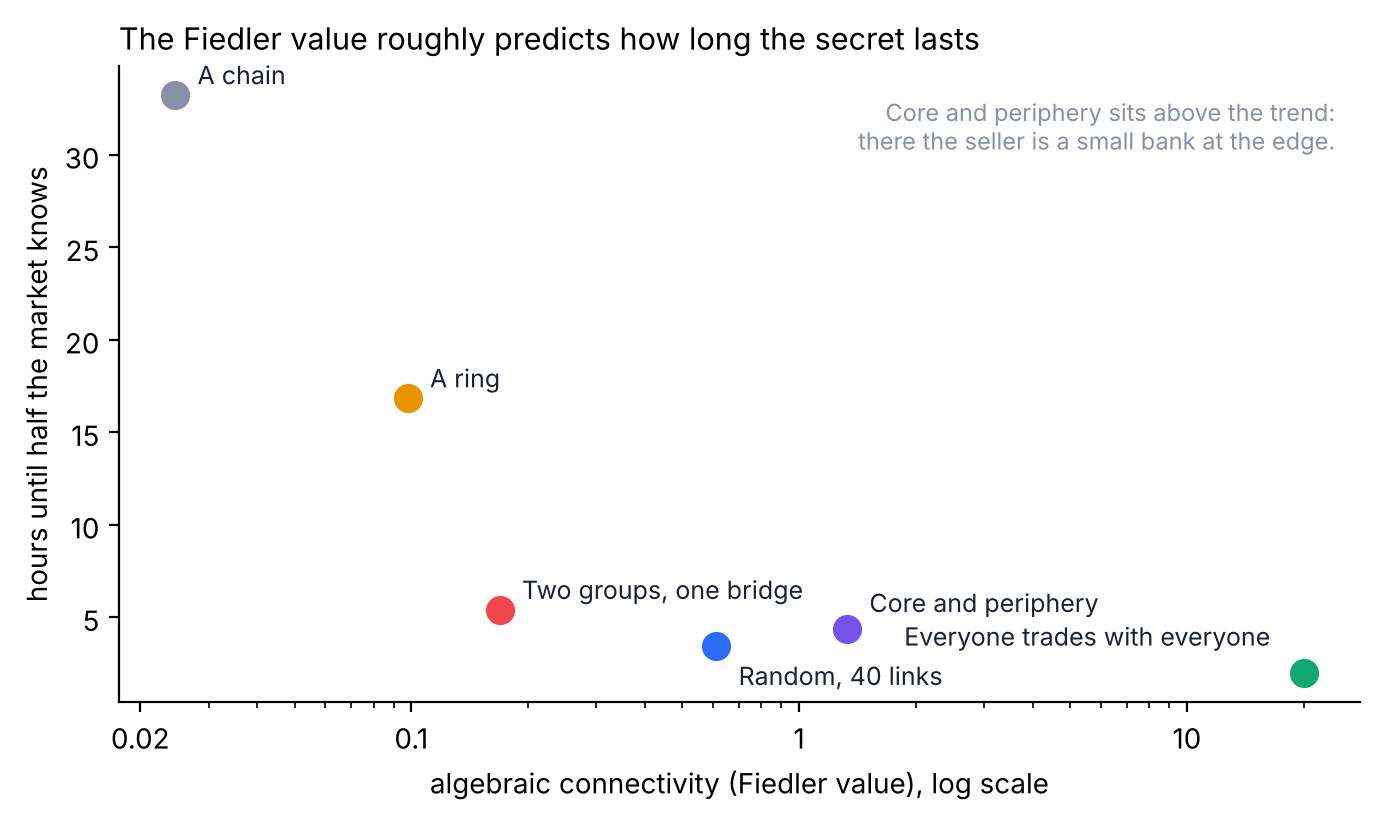

In [5]:
# Figure 2: the spectral number predicts the window
fig, ax = plt.subplots(figsize=(7, 4.2))
offsets = {"Random, 40 links": (8, -14), "Core and periphery": (8, 6),
           "Everyone trades with everyone": (-12, 10)}
for (name, r), col in zip(results.items(), COLORS):
    ax.scatter(r[1], r[3], s=90, color=col, zorder=3)
    dx, dy = offsets.get(name, (8, 4))
    ax.annotate(name, (r[1], r[3]), xytext=(dx, dy), textcoords="offset points", fontsize=9,
                color=INK, ha="right" if dx < 0 else "left")
ax.set_xscale("log")
ax.set_xticks([0.02, 0.1, 1, 10])
ax.get_xaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("algebraic connectivity (Fiedler value), log scale")
ax.set_ylabel("hours until half the market knows")
ax.set_title("The Fiedler value roughly predicts how long the secret lasts", loc="left", fontsize=11)
ax.text(0.98, 0.95, "Core and periphery sits above the trend:\nthere the seller is a small bank at the edge.",
        transform=ax.transAxes, fontsize=8.5, color=MUTED, ha="right", va="top")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("market_fig2_fiedler.png", dpi=160)
print("\nSaved market_fig1_who_knows.png and market_fig2_fiedler.png")